# Weighted PageRank in Tennis — Part 3
**Chakib Madcur · Progress update**

What we agreed on 10/7:
1. Compare **weighted PageRank and the ATP ranking as vectors** with **cosine similarity** (2 players, 10, 50, 100), and explain why cosine and not Euclidean distance
2. Find out **which measure last week's table used** and how it relates to cosine and Euclidean distance
3. Compare **through time**: past seasons, and the years when the ATP changed its ranking rules
4. Apply PageRank to the **English Premier League** (a league, not a knockout tournament)

## Step 1 · Setup
Same data and the same weighted PageRank as in Parts 1 and 2 (edge weight = matches won, node weight = matches won + 1).

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

DATA = "https://raw.githubusercontent.com/Aneeshers/tennis-sackmann-archive/main/atp/"   # copy of Jeff Sackmann's data
os.makedirs("figures", exist_ok=True)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})

def load_season(year):
    m = pd.read_csv(DATA + f"atp_matches_{year}.csv")
    return m[(m.tourney_level != "D") & (m.tourney_name != "Next Gen Finals")
             & (~m.score.astype(str).str.contains("W/O", na=False))]

def build_graph(m):
    G = nx.DiGraph()                                   # arrow: loser -> winner, weight = matches won
    for loser, winner in zip(m.loser_id, m.winner_id):
        if G.has_edge(loser, winner):
            G[loser][winner]["weight"] += 1
        else:
            G.add_edge(loser, winner, weight=1)
    return G

def pagerank_scores(m, G):
    wins = m.winner_id.value_counts()
    node_weight = {p: wins.get(p, 0) + 1 for p in G}   # node weight = matches won + 1
    return pd.Series(nx.pagerank(G, alpha=0.85, personalization=node_weight, weight="weight", tol=1e-12))

RANKING_FILES = ["atp_rankings_70s.csv", "atp_rankings_80s.csv", "atp_rankings_90s.csv",
                 "atp_rankings_00s.csv", "atp_rankings_10s.csv", "atp_rankings_20s.csv"]
rankings = pd.concat([pd.read_csv(DATA + f) for f in RANKING_FILES])

def atp_year_end(year):
    last = rankings[rankings.ranking_date <= year * 10000 + 1231].ranking_date.max()
    return rankings[rankings.ranking_date == last].set_index("player")[["rank", "points"]]

names = {}
def remember_names(m):
    names.update(dict(zip(m.winner_id, m.winner_name)) | dict(zip(m.loser_id, m.loser_name)))

m25, m15 = load_season(2025), load_season(2015)
remember_names(m25); remember_names(m15)
pr25, pr15 = pagerank_scores(m25, build_graph(m25)), pagerank_scores(m15, build_graph(m15))
atp25, atp15 = atp_year_end(2025), atp_year_end(2015)
print("Ready: 2015 and 2025 seasons loaded")

Ready: 2015 and 2025 seasons loaded


## Step 2 · Cosine similarity between PageRank and ATP

For the ATP top N players I build **two vectors of length N**:
- **ATP vector:** each player's ATP ranking points (for example 12,050 for Alcaraz)
- **PageRank vector:** each player's weighted PageRank score from the full season graph (for example 0.0589 for Alcaraz)

**Cosine similarity** measures the angle between the two vectors:

$$\cos(\mathbf{a},\mathbf{p}) = \frac{\mathbf{a}\cdot\mathbf{p}}{\|\mathbf{a}\|\,\|\mathbf{p}\|}$$

It equals 1 when the two vectors point in the same direction, meaning both systems give the players the same *proportions*, even if one system uses thousands of points and the other uses small probabilities.

In [2]:
def cosine(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

def vectors(atp, pr, N):
    top = atp[atp["rank"] <= N].sort_values("rank")
    top = top[top.index.isin(pr.index)]                # players who played at least one tour-level match
    return top.points.values, pr[top.index].values, top.index

# Example with 2 players: Alcaraz and Sinner, 2025
a, p, ids = vectors(atp25, pr25, 2)
print(pd.DataFrame({"Player": [names[i] for i in ids], "ATP points": a, "PageRank score": p.round(4)}).to_string(index=False))
print(f"\nCosine similarity (2 players): {cosine(a, p):.3f}")

        Player  ATP points  PageRank score
Carlos Alcaraz     12050.0          0.0589
 Jannik Sinner     11500.0          0.0422

Cosine similarity (2 players): 0.990


**A check on what cosine means here.** All points and PageRank scores are positive, so cosine is always above 0 and often high. To know whether a value like 0.97 is *really* high, I compare it with a **random baseline**: the average cosine when the PageRank scores are shuffled at random among the same players (so there is no relation at all).

In [3]:
rng = np.random.default_rng(0)

def cosine_table(atp, pr):
    rows = {}
    for N in [2, 5, 10, 20, 50, 100]:
        a, p, ids = vectors(atp, pr, N)
        baseline = np.mean([cosine(a, rng.permutation(p)) for _ in range(2000)])
        rows[f"Top {N}"] = {"Players": len(ids), "Cosine similarity": cosine(a, p), "Random baseline": baseline}
    t = pd.DataFrame(rows).T
    t["Players"] = t["Players"].astype(int)
    return t

cos25, cos15 = cosine_table(atp25, pr25), cosine_table(atp15, pr15)
pd.concat({"2015": cos15, "2025": cos25}, axis=1).round(3)

2015                                      2025                    \
        Players Cosine similarity Random baseline Players Cosine similarity   
Top 2         2             1.000           0.910       2             0.990   
Top 5         5             0.977           0.858       5             0.992   
Top 10       10             0.977           0.721      10             0.988   
Top 20       20             0.977           0.583      20             0.980   
Top 50       50             0.968           0.468      50             0.972   
Top 100      99             0.965           0.353     100             0.969   

                         
        Random baseline  
Top 2             0.986  
Top 5             0.827  
Top 10            0.780  
Top 20            0.733  
Top 50            0.616  
Top 100           0.502

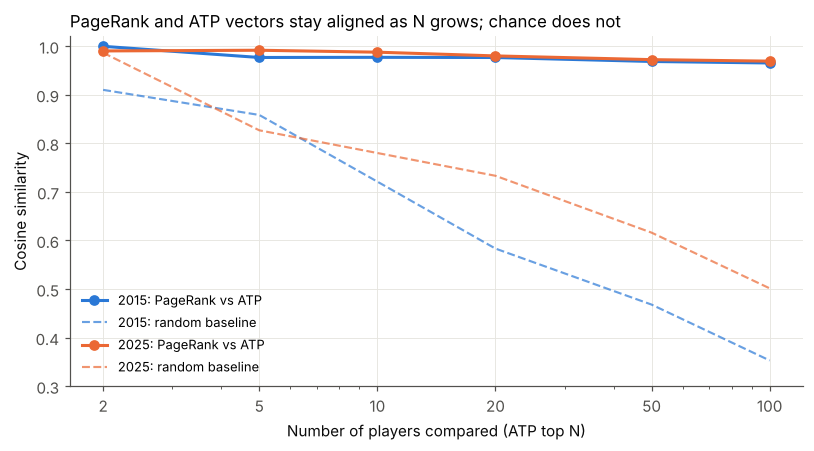

In [4]:
Ns = [2, 5, 10, 20, 50, 100]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for year, t, color in [("2015", cos15, BLUE), ("2025", cos25, ORANGE)]:
    ax.plot(Ns, t["Cosine similarity"], "-o", color=color, lw=2, ms=6, label=f"{year}: PageRank vs ATP")
    ax.plot(Ns, t["Random baseline"], "--", color=color, lw=1.4, alpha=0.7, label=f"{year}: random baseline")
ax.set_xscale("log"); ax.set_xticks(Ns); ax.set_xticklabels(Ns)
ax.set_ylim(0.3, 1.02); ax.set_xlabel("Number of players compared (ATP top N)"); ax.set_ylabel("Cosine similarity")
ax.set_title("PageRank and ATP vectors stay aligned as N grows; chance does not", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
plt.tight_layout(); plt.savefig("figures/cosine_by_N.png", dpi=200); plt.show()

**Why cosine similarity and not Euclidean distance**
- **Different scales.** ATP points are in the thousands; PageRank scores are probabilities that add up to 1. The Euclidean distance between the raw vectors is almost entirely the size of the ATP numbers, so it says nothing about whether the two systems agree. Cosine ignores the length of each vector and only compares the *relations* between players.
- **Comparable across N.** Euclidean distance grows as more players (more dimensions) are added, so a top-10 and a top-100 value cannot be compared. Cosine always stays between 0 and 1 here.
- **Euclidean after rescaling is the same as cosine.** If both vectors are first scaled to length 1, the Euclidean distance becomes √(2·(1 − cos)), so it carries exactly the same information as cosine. Cosine is the simpler way to say it.

In [5]:
rows = {}
for N in [10, 50, 100]:
    a, p, _ = vectors(atp25, pr25, N)
    rows[f"Top {N}"] = {"Euclidean (raw vectors)": np.linalg.norm(a - p),
                        "Euclidean (both scaled to length 1)": np.linalg.norm(a / np.linalg.norm(a) - p / np.linalg.norm(p)),
                        "√(2·(1 − cosine))": np.sqrt(2 * (1 - cosine(a, p)))}
pd.DataFrame(rows).T.style.format({"Euclidean (raw vectors)": "{:,.0f}", "Euclidean (both scaled to length 1)": "{:.3f}",
                                   "√(2·(1 − cosine))": "{:.3f}"}).set_caption("2025 season")

,Euclidean (raw vectors),Euclidean (both scaled to length 1),√(2·(1 − cosine))
Top 10,"20,451",0.157,0.157
Top 50,"23,245",0.236,0.236
Top 100,"23,903",0.248,0.248


## Step 3 · Which measure was last week's table?
Last week's first column (2015: **0.98, 0.85, 0.93**) was **Spearman's rank correlation**. It compares the two *orders* (1st, 2nd, 3rd…), not the sizes of the scores. It is connected to both measures:
- It is the **cosine similarity of the two rank vectors after subtracting their average** (a "centered" cosine).
- It is also a **rescaled squared Euclidean distance between the rank vectors**: ρ = 1 − 6·Σd² / (n(n² − 1)), where Σd² is the squared Euclidean distance between the ranks.

The code checks that the three give the same number.

In [6]:
rows = {}
for N in [10, 50, 100]:
    a, p, _ = vectors(atp15, pr15, N)
    ra = pd.Series(a).rank(ascending=False).values          # ATP order within the top N
    rp = pd.Series(p).rank(ascending=False).values          # PageRank order of the same players
    n = len(ra)
    rows[f"Top {N}"] = {"Spearman (last week)": spearmanr(a, p)[0],
                        "Centered cosine of ranks": cosine(ra - ra.mean(), rp - rp.mean()),
                        "1 − 6·Σd²/(n(n²−1))": 1 - 6 * np.sum((ra - rp) ** 2) / (n * (n ** 2 - 1)),
                        "Cosine of scores (this week)": cosine(a, p)}
pd.DataFrame(rows).T.round(3).style.format("{:.3f}").set_caption("2015 season — PageRank vs ATP, full graph")

,Spearman (last week),Centered cosine of ranks,1 − 6·Σd²/(n(n²−1)),Cosine of scores (this week)
Top 10,0.976,0.976,0.976,0.977
Top 50,0.850,0.850,0.850,0.968
Top 100,0.935,0.935,0.935,0.965


So last week's measure compared **orders** with equal weight for every position, while this week's cosine compares **scores**, where the top players (with the largest values) count the most. Both say the two rankings agree strongly; cosine is higher because the top of both rankings agrees best.

## Step 4 · Through time: every season since 1973
I run the same comparison (ATP top 100, full-season graph) for every season. Spearman can be computed for every year; cosine needs ATP points, which the dataset has for the year-end ranking from 1996 on.

The ATP changed its ranking rules several times:
- **1973–1989:** ranking based on each player's **average** result
- **1990:** a **"best of" system** (sum of the best 14 results)
- **2000:** best **18** results
- **2009:** last major overhaul of the points table
- **2020–2022:** COVID-19 — ranking frozen in March 2020, then a "best 18 results from March 2019 to December 2020" system; normal 52-week rules fully back in August 2022

In [7]:
rows = []
for year in range(1973, 2026):
    m = load_season(year); remember_names(m)
    pr = pagerank_scores(m, build_graph(m))
    atp = atp_year_end(year)
    top = atp[atp["rank"] <= 100]
    top = top[top.index.isin(pr.index)]
    has_points = top.points.notna().all()
    rows.append({"Season": year,
                 "Spearman": spearmanr(top["rank"], -pr[top.index])[0],
                 "Cosine": cosine(top.points, pr[top.index]) if has_points else np.nan,
                 "ATP #1": names.get(atp[atp["rank"] == 1].index[0]),
                 "PageRank #1": names.get(pr.idxmax()),
                 "Top-10 overlap": len(set(atp[atp["rank"] <= 10].index) & set(pr.nlargest(10).index))})
history = pd.DataFrame(rows).set_index("Season")
print("Average Spearman 1973–1989:", round(history.loc[1973:1989, "Spearman"].mean(), 3))
print("Average Spearman 1990–2019:", round(history.loc[1990:2019, "Spearman"].mean(), 3))
print("Average cosine   1996–2025:", round(history.loc[1996:2025, "Cosine"].mean(), 3))

Average Spearman 1973–1989: 0.857
Average Spearman 1990–2019: 0.911
Average cosine   1996–2025: 0.966


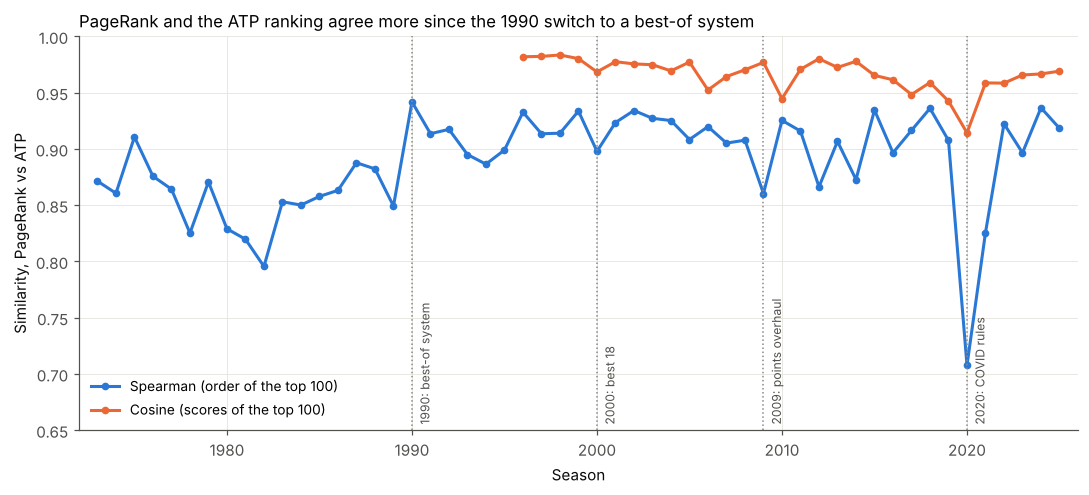

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(history.index, history.Spearman, "-o", color=BLUE, lw=2, ms=4, label="Spearman (order of the top 100)")
ax.plot(history.index, history.Cosine, "-o", color=ORANGE, lw=2, ms=4, label="Cosine (scores of the top 100)")
for x, label in [(1990, "1990: best-of system"), (2000, "2000: best 18"), (2009, "2009: points overhaul"), (2020, "2020: COVID rules")]:
    ax.axvline(x, color=GREY, lw=1, ls=":")
    ax.text(x + 0.3, 0.655, label, rotation=90, va="bottom", fontsize=8, color="#52514e")
ax.set_ylim(0.65, 1.0); ax.set_xlim(1972, 2026)
ax.set_xlabel("Season"); ax.set_ylabel("Similarity, PageRank vs ATP")
ax.set_title("PageRank and the ATP ranking agree more since the 1990 switch to a best-of system", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="lower left")
plt.tight_layout(); plt.savefig("figures/agreement_through_time.png", dpi=200); plt.show()

**Selected seasons** — who was #1 in each system:

In [9]:
history.loc[[1975, 1978, 1985, 1990, 1995, 2005, 2010, 2015, 2020, 2022, 2025]].round(3)

,Spearman,Cosine,ATP #1,PageRank #1,Top-10 overlap
Season,,,,,
1975,0.911,NaN,Jimmy Connors,Arthur Ashe,8
1978,0.825,NaN,Jimmy Connors,Bjorn Borg,7
1985,0.858,NaN,Ivan Lendl,Ivan Lendl,8
1990,0.942,NaN,Stefan Edberg,Stefan Edberg,8
1995,0.899,NaN,Pete Sampras,Pete Sampras,9
2005,0.908,0.977,Roger Federer,Roger Federer,8
2010,0.925,0.945,Rafael Nadal,Roger Federer,8
2015,0.935,0.965,Novak Djokovic,Novak Djokovic,8
2020,0.708,0.914,Novak Djokovic,Novak Djokovic,8


## Step 5 · PageRank in the English Premier League (2025–26)
The Premier League is a **league**: all 20 teams play each other twice (380 matches), so every team faces the same opponents. Tennis is a **tour of knockout tournaments**: each player meets a different set of opponents. I apply the same program to see how much PageRank adds in each case.

Graph: arrow from the loser to the winner (weight 1). A **draw counts as half a win for each team** (two arrows of weight 0.5). Node weight = wins + draws/2 + 1.

In [10]:
EPL = "https://raw.githubusercontent.com/datasets/football-datasets/main/datasets/premier-league/season-2526.csv"
epl = pd.read_csv(EPL, parse_dates=["Date"])

def league_table(d):
    rows = []
    for r in d.itertuples():
        rows += [(r.HomeTeam, r.FTHG, r.FTAG), (r.AwayTeam, r.FTAG, r.FTHG)]
    t = pd.DataFrame(rows, columns=["Team", "GF", "GA"])
    t = t.assign(W=t.GF > t.GA, D=t.GF == t.GA, L=t.GF < t.GA)
    T = t.groupby("Team").agg(P=("GF", "size"), W=("W", "sum"), D=("D", "sum"), L=("L", "sum"), GF=("GF", "sum"), GA=("GA", "sum"))
    T["GD"], T["Pts"] = T.GF - T.GA, 3 * T.W + T.D
    T = T.sort_values(["Pts", "GD", "GF"], ascending=False)
    T.insert(0, "Pos", range(1, len(T) + 1))
    return T

def football_graph(d):
    G = nx.DiGraph(); G.add_nodes_from(set(d.HomeTeam) | set(d.AwayTeam))
    def add(u, v, w):
        G.add_edge(u, v, weight=G[u][v]["weight"] + w if G.has_edge(u, v) else w)
    for r in d.itertuples():
        if r.FTHG < r.FTAG:   add(r.HomeTeam, r.AwayTeam, 1)       # home team lost
        elif r.FTHG > r.FTAG: add(r.AwayTeam, r.HomeTeam, 1)       # away team lost
        else:                 add(r.HomeTeam, r.AwayTeam, 0.5); add(r.AwayTeam, r.HomeTeam, 0.5)
    return G

def football_pagerank(d):
    T, G = league_table(d), football_graph(d)
    node_weight = {t: T.W[t] + T.D[t] / 2 + 1 for t in G}
    return pd.Series(nx.pagerank(G, alpha=0.85, personalization=node_weight, weight="weight", tol=1e-12))

table = league_table(epl)
pr_epl = football_pagerank(epl)
table["PageRank"] = pr_epl.rank(ascending=False).astype(int)[table.index]
print(f"{len(epl)} matches, {len(table)} teams")
table[["Pos", "Pts", "W", "D", "L", "GD", "PageRank"]]

380 matches, 20 teams


,Pos,Pts,W,D,L,GD,PageRank
Team,,,,,,,
Arsenal,1,85,26,7,5,44,2
Man City,2,78,23,9,6,42,1
Man United,3,71,20,11,7,19,3
Aston Villa,4,65,19,8,11,7,4
Liverpool,5,60,17,9,12,10,6
Bournemouth,6,57,13,18,7,4,5
Sunderland,7,54,14,12,12,-6,8
Brighton,8,53,14,11,13,6,9
Brentford,9,53,14,11,13,3,7


In [11]:
base = np.mean([cosine(table.Pts, rng.permutation(pr_epl[table.index].values)) for _ in range(2000)])
print(f"Spearman (table position vs PageRank): {spearmanr(table.Pos, table.PageRank)[0]:.3f}")
print(f"Cosine (points vs PageRank score):      {cosine(table.Pts, pr_epl[table.index]):.3f}   (random baseline {base:.3f})")

Spearman (table position vs PageRank): 0.965
Cosine (points vs PageRank score):      0.997   (random baseline 0.923)


**Why Manchester City is #1 in PageRank but Arsenal won the league:** results among the top six teams.

In [12]:
top6 = list(table.index[:6])
h = epl[epl.HomeTeam.isin(top6) & epl.AwayTeam.isin(top6)]
rec = {}
for t in ["Arsenal", "Man City"]:
    gf = list(h[h.HomeTeam == t].FTHG) + list(h[h.AwayTeam == t].FTAG)
    ga = list(h[h.HomeTeam == t].FTAG) + list(h[h.AwayTeam == t].FTHG)
    rec[t] = {"W": sum(x > y for x, y in zip(gf, ga)), "D": sum(x == y for x, y in zip(gf, ga)), "L": sum(x < y for x, y in zip(gf, ga))}
print("Record against the other top-6 teams:"); display(pd.DataFrame(rec).T)
display(h[(h.HomeTeam.isin(["Arsenal", "Man City"])) & (h.AwayTeam.isin(["Arsenal", "Man City"]))][["Date", "HomeTeam", "FTHG", "FTAG", "AwayTeam"]])

Record against the other top-6 teams:


,W,D,L
Arsenal,3,2,5
Man City,5,2,3


,Date,HomeTeam,FTHG,FTAG,AwayTeam
49,2025-09-21,Arsenal,1,1,Man City
327,2026-04-19,Man City,2,1,Arsenal


**Extra: when does PageRank help in a league?** Early in the season each team has met only a few opponents, like in tennis. I take the results after about 5, 10 and 19 games per team and check which one predicts the **final table** better: the points so far, or PageRank so far.

In [13]:
epl_sorted = epl.sort_values("Date")
rows = {}
for k in [5, 10, 19]:
    played = {t: 0 for t in table.index}; keep = []
    for r in epl_sorted.itertuples():
        if played[r.HomeTeam] < k and played[r.AwayTeam] < k:
            keep.append(r.Index); played[r.HomeTeam] += 1; played[r.AwayTeam] += 1
    part = epl_sorted.loc[keep]
    pts_so_far = league_table(part).Pts[table.index]
    pr_so_far = football_pagerank(part)[table.index]
    rows[f"After ~{k} games"] = {"Matches": len(part),
                                 "Points so far vs final table": spearmanr(table.Pos, -pts_so_far)[0],
                                 "PageRank so far vs final table": spearmanr(table.Pos, -pr_so_far)[0]}
early = pd.DataFrame(rows).T
early["Matches"] = early["Matches"].astype(int)
early.round(3)

,Matches,Points so far vs final table,PageRank so far vs final table
After ~5 games,50,0.382,0.550
After ~10 games,100,0.796,0.802
After ~19 games,190,0.832,0.792


## Findings
1. **Cosine similarity confirms strong agreement.** For the ATP top 10, 50 and 100, cosine between the PageRank and ATP vectors is **0.97–0.99** in both 2015 and 2025, far above the random baseline (0.35–0.78), and the gap grows with N.
2. **With only 2 players, cosine is not informative:** the random baseline is already 0.91–0.99, because both vectors are positive. The comparison becomes meaningful from about 10 players on.
3. **Last week's table used Spearman's rank correlation**, which compares orders. It equals the centered cosine of the rank vectors and is a rescaled Euclidean distance between ranks. This week's cosine compares the scores themselves.
4. **Different approaches give similar rankings.** PageRank (who beat whom) and the ATP ranking (points by tournament and round) are built in completely different ways, yet agree with cosine ≈ 0.97 almost every season.
5. **History:** agreement was lower when the ATP ranked players by their average result (1973–1989, Spearman ≈ 0.86) and higher after the 1990 best-of system (≈ 0.91). It dropped in **2020 (0.71)**, when COVID rules made the ranking cover March 2019–December 2020 while PageRank only uses 2020 matches.
6. **Premier League:** PageRank almost reproduces the final table (Spearman 0.97, cosine 0.997). It ranks **Manchester City first**, ahead of champions Arsenal, because City did better against the other top teams (5 wins, 2 draws, 3 losses vs Arsenal's 3–2–5) and took 4 points from Arsenal.
7. **League vs tournament:** in a league where everyone plays everyone, points already account for the schedule, so PageRank adds little by the end. Early in the season (after ~5 games) PageRank predicts the final table better than points (0.55 vs 0.38), which matches the idea that PageRank helps most when teams or players have met only some of the possible opponents, as in tennis. This is one season only.